# Ledger Sentinel — analysis

**Question.** Can an accounts-payable team catch fraudulent supplier invoices — duplicate payments, vendor impersonation, phantom vendors — without burying analysts in false alarms, and without the model learning to suspect vendors because of where they are based?

This notebook is the data science half of the project: exploratory analysis, model comparison, uncertainty estimates, a fairness audit, and what the resulting agent does to a real payment queue. The pipeline that produces the data and models is in `src/` and runs with `./run_all.sh`.

**Headline results** (held-out test set: the final 20% of the ledger by time, 614 invoices, 31 fraudulent)

| | |
|---|---|
| The rule an AP team writes first | catches **16%** of fraud at **12%** precision |
| Shipped model (depth-6 decision tree) | catches **90%** of fraud (95% CI 79–100%) at **56%** precision |
| Agent routing | sends **12%** of invoices to review; that slice holds **93%** of fraudulent dollars |
| Same model allowed to see vendor region | false-alarm rate on clean South Asian vendors **62%**, vs **16%** without it |

> **All data is synthetic.** Real AP ledgers are confidential. Every number measures whether the method recovers patterns deliberately planted in a simulated ledger — see the limitations at the end.

## Setup

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent
assert (ROOT / "src" / "analysis.py").exists(), "Run this notebook from the notebooks/ folder, after ./run_all.sh"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Image, display

import analysis as A
import figstyle as S

S.apply()
pd.set_option("display.precision", 3)
FIG = ROOT / "out" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

bundle, train, test = A.load()
validation = pd.read_csv("data/validation.csv")
ledger = pd.concat([train, test], ignore_index=True)   # train.csv already contains the validation rows
assert len(ledger) == len(pd.read_csv("data/invoices.csv"))

y = test["true_fraud"].to_numpy()
probs = A.scored_models(bundle, test)
preds = {name: A.hard(p) for name, p in probs.items()}

## 1. The data

A simulated two-year ledger: 162 vendors, three fraud schemes planted at known points. The legitimate side is built to look superficially suspicious on purpose — recurring vendors bill near-identical invoices every month, honest vendors do change banks, some honest invoices are round numbers or arrive at night — so no single feature gives the answer away.

**The labels are deliberately imperfect.** A model is trained on what past investigators *wrote down*, not on ground truth. In this ledger one region spent years under a standing "enhanced scrutiny" policy, so a share of its clean invoices carry a fraud label they never earned. Models train on those historical labels and are scored against the truth.

In [2]:
overview = pd.Series({
    "invoices": len(ledger),
    "vendors": ledger["vendor_id"].nunique(),
    "truly fraudulent": int(ledger["true_fraud"].sum()),
    "fraud rate": f"{ledger['true_fraud'].mean():.1%}",
    "labelled fraud in historical records": int(ledger["historical_label"].sum()),
    "  of which actually clean": int(((ledger["historical_label"] == 1) & (ledger["true_fraud"] == 0)).sum()),
}, name="ledger")
display(overview.to_frame())

display(ledger.loc[ledger["true_fraud"] == 1, "fraud_type"].value_counts().rename("invoices").to_frame("fraud scheme"))

,ledger
invoices,3061
vendors,162
truly fraudulent,144
fraud rate,4.7%
labelled fraud in historical records,241
of which actually clean,97


,fraud scheme
fraud_type,
duplicate_payment,55
bank_swap,45
phantom_vendor,44


Where the wrong labels sit — the bias the models will be exposed to:

In [3]:
clean = ledger[ledger["true_fraud"] == 0]
label_bias = clean.groupby("region")["historical_label"].agg(clean_invoices="size", labelled_fraud="sum")
label_bias["share_mislabelled"] = label_bias["labelled_fraud"] / label_bias["clean_invoices"]
label_bias.sort_values("share_mislabelled", ascending=False)

,clean_invoices,labelled_fraud,share_mislabelled
region,,,
South Asia,462,97,0.21
East Asia,639,0,0.00
Europe,611,0,0.00
Latin America,576,0,0.00
North America,629,0,0.00


**Splitting by time, not at random.** A random split would let a model learn from March to predict January. Fraud detection is forecasting, so the three slices are consecutive: fit on the past, tune on the next slice, and open the test slice exactly once.

In [4]:
def describe(frame):
    return pd.Series({
        "first day": int(frame["day"].min()),
        "last day": int(frame["day"].max()),
        "invoices": len(frame),
        "fraudulent": int(frame["true_fraud"].sum()),
    })

fit_only = train[train["day"] < bundle["train_cut"]]
pd.DataFrame({
    "train": describe(fit_only),
    "validation (tuning)": describe(validation),
    "test (sealed)": describe(test),
}).T

,first day,last day,invoices,fraudulent
train,0,466,1835,89
validation (tuning),467,600,612,24
test (sealed),601,729,614,31


## 2. Why the obvious rule fails, and what replaces it

The first thing anyone writes is *"flag an invoice that looks almost identical to one we already paid."* The left panel shows why that fails: most **legitimate** invoices look almost identical to an earlier one, because recurring suppliers send the same bill every cycle.

The right panel is the feature that does separate them. A duplicate isn't unusual because it resembles an old invoice. It's unusual because it arrives **too early for that vendor**. The ratio compares the days since the vendor's last invoice with that vendor's typical gap. Honest invoices cluster near 1, on schedule. Duplicates arrive at a small fraction of the usual gap.

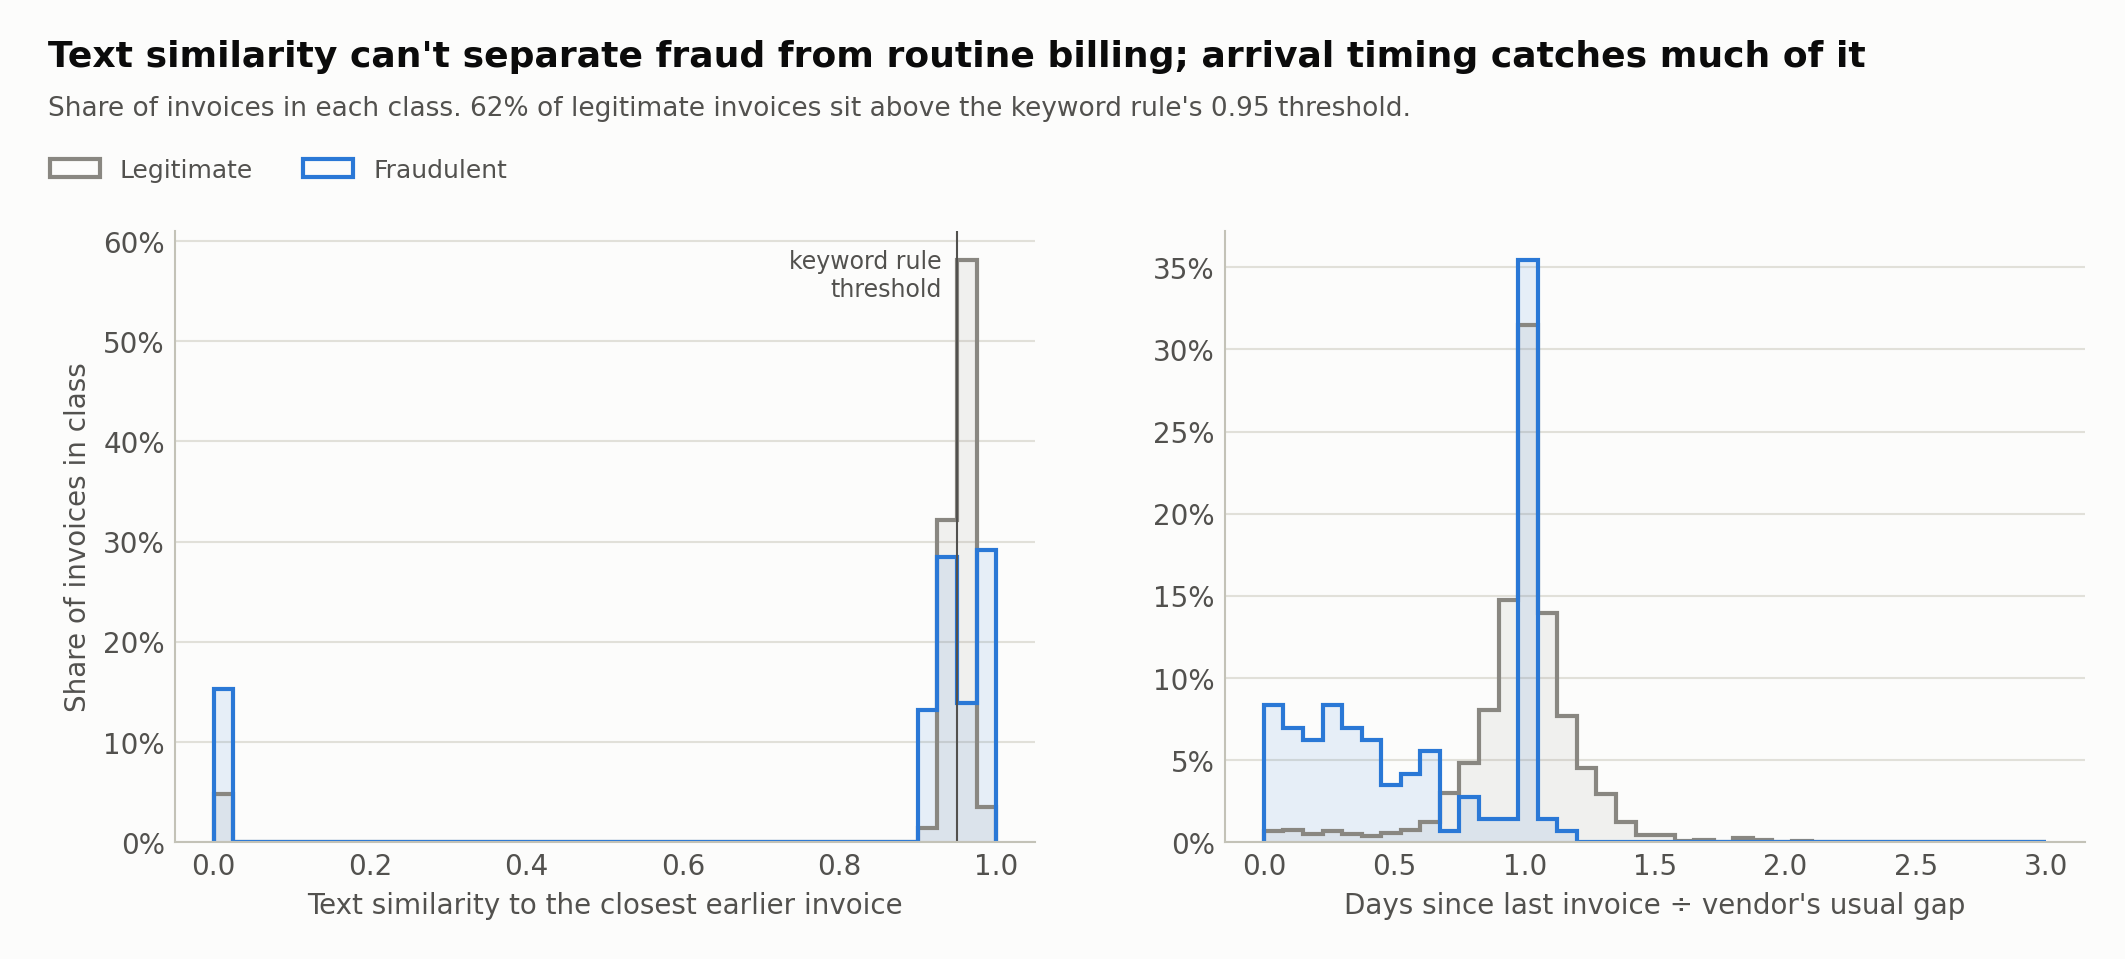

,above 0.95 similarity,median early-arrival ratio
legitimate,0.616,1.000
fraudulent,0.431,0.593


In [5]:
legit = ledger[ledger["true_fraud"] == 0]
fraud = ledger[ledger["true_fraud"] == 1]
legit_above = (legit["max_similarity_to_prior"] > 0.95).mean()
fraud_above = (fraud["max_similarity_to_prior"] > 0.95).mean()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
legend_y = S.heading(
    fig,
    "Text similarity can't separate fraud from routine billing; arrival timing catches much of it",
    f"Share of invoices in each class. {legit_above:.0%} of legitimate invoices sit above the keyword rule's 0.95 threshold.",
    left=0.075,
)
fig.subplots_adjust(wspace=0.22, right=0.985)

panels = [
    (axes[0], "max_similarity_to_prior", np.linspace(0, 1, 41), None,
     "Text similarity to the closest earlier invoice"),
    (axes[1], "gap_vs_vendor_cadence", np.linspace(0, 3, 41), 3,
     "Days since last invoice ÷ vendor's usual gap"),
]
for ax, column, bins, cap, xlabel in panels:
    for frame, color, name in ((legit, S.CLEAN_COLOR, "Legitimate"), (fraud, S.FRAUD_COLOR, "Fraudulent")):
        values = frame[column] if cap is None else frame[column].clip(upper=cap)
        weights = np.full(len(values), 1 / len(values))
        ax.hist(values, bins=bins, weights=weights, histtype="stepfilled", color=color, alpha=0.10)
        ax.hist(values, bins=bins, weights=weights, histtype="step", color=color,
                linewidth=S.LINE_W, label=name)
    ax.set_xlabel(xlabel)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of invoices in class")

axes[0].axvline(0.95, color=S.INK_2, linewidth=S.HAIRLINE)
axes[0].text(0.93, axes[0].get_ylim()[1] * 0.97, "keyword rule\nthreshold", ha="right", va="top",
             fontsize=8.5, color=S.INK_2)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.005, legend_y), ncol=2)

S.save(fig, FIG / "01_similarity_vs_timing.png")
display(Image(filename=FIG / "01_similarity_vs_timing.png", width=900, alt="Two histograms. Left: most legitimate and fraudulent invoices are over 90 percent similar to an earlier invoice, so similarity does not separate them. Right: fraudulent invoices arrive well before the vendor's usual billing gap, while legitimate ones cluster at the usual gap."))

pd.DataFrame({
    "above 0.95 similarity": [legit_above, fraud_above],
    "median early-arrival ratio": [legit["gap_vs_vendor_cadence"].median(), fraud["gap_vs_vendor_cadence"].median()],
}, index=["legitimate", "fraudulent"])

The spike at exactly 1.0 on the right is invoices from vendors with too little history to have a rhythm yet. They default to 1, and that group includes every phantom vendor. Timing catches duplicates and many impersonations; phantom vendors need other signals (vendor age, round amounts, missing purchase orders), which is why the model combines features rather than relying on one.

## 3. Model comparison

Four models trained on identical features and identical (historical) labels, plus the keyword rule as a baseline. Hyperparameters were tuned on the validation slice using an explicit cost ratio: a missed fraud costs six times a false alarm.

Precision–recall curves are used instead of ROC because fraud is rare (5% here), and ROC curves flatter models on imbalanced data. Average precision (AP) summarises each curve.

In [6]:
metrics = A.metrics_table(y, probs, A.keyword_rule(test))
metrics

,precision,recall,f1,average_precision,flagged,false_alarms,missed
Keyword rule,0.116,0.161,0.135,NaN,43.0,38.0,26.0
Decision tree (shipped),0.560,0.903,0.691,0.828,50.0,22.0,3.0
Random forest,0.897,0.839,0.867,0.943,29.0,3.0,5.0
Logistic regression,0.459,0.903,0.609,0.869,61.0,33.0,3.0
Decision tree + region,0.298,0.903,0.448,0.639,94.0,66.0,3.0


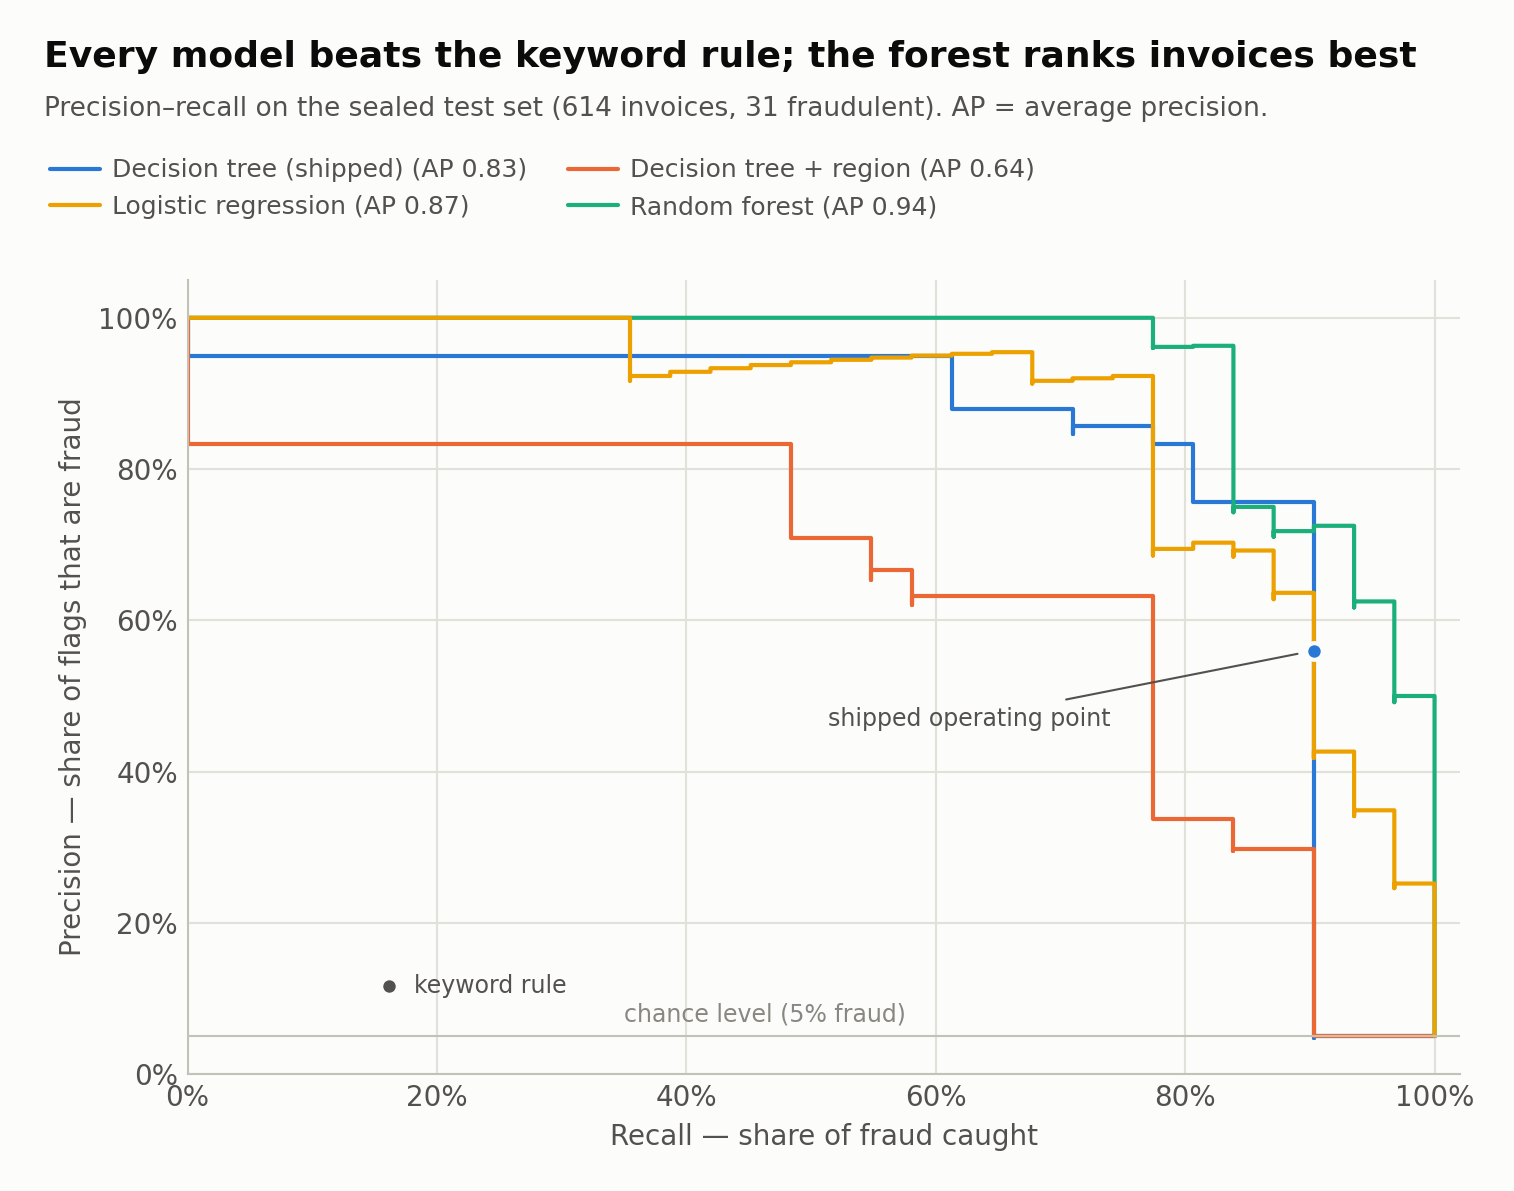

In [7]:
order = [A.TREE, A.NAIVE, A.FOREST, A.LOGISTIC]  # validated colour-slot order
fig, ax = plt.subplots(figsize=(8, 5.9))
legend_y = S.heading(
    fig,
    "Every model beats the keyword rule; the forest ranks invoices best",
    "Precision–recall on the sealed test set (614 invoices, 31 fraudulent). AP = average precision.",
    left=0.105,
    legend_rows=2,
)
for name in order:
    recall, precision, ap = A.pr_curve(y, probs[name])
    ax.plot(recall, precision, drawstyle="steps-post", color=S.MODEL_COLORS[name], label=f"{name} (AP {ap:.2f})")

shipped = metrics.loc[A.TREE]
ax.plot(shipped["recall"], shipped["precision"], "o", ms=S.MARKER, color=S.MODEL_COLORS[A.TREE],
        mec=S.SURFACE, mew=S.RING, zorder=5)
ax.annotate("shipped operating point", (shipped["recall"], shipped["precision"]), xytext=(0.74, 0.47),
            textcoords="data", ha="right", va="center", fontsize=8.5, color=S.INK_2,
            arrowprops=dict(arrowstyle="-", color=S.INK_2, linewidth=S.HAIRLINE, shrinkA=3, shrinkB=6))

rule = metrics.loc[A.RULE]
ax.plot(rule["recall"], rule["precision"], "o", ms=S.MARKER, color=S.INK_2, mec=S.SURFACE, mew=S.RING, zorder=5)
ax.annotate("keyword rule", (rule["recall"], rule["precision"]), xytext=(9, 0),
            textcoords="offset points", va="center", fontsize=8.5, color=S.INK_2)

base_rate = y.mean()
ax.axhline(base_rate, color=S.BASELINE, linewidth=S.HAIRLINE)
ax.text(0.35, base_rate + 0.012, f"chance level ({base_rate:.0%} fraud)", ha="left", va="bottom",
        fontsize=8.5, color=S.MUTED)

ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.05)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Recall — share of fraud caught")
ax.set_ylabel("Precision — share of flags that are fraud")
# Two columns fill top-down, so this places orange and yellow diagonally: the one
# colour pair that is too close to sit side by side never touches.
handles, labels = ax.get_legend_handles_labels()
pick = [0, 3, 1, 2]
fig.legend([handles[i] for i in pick], [labels[i] for i in pick], loc="upper left",
           bbox_to_anchor=(0.005, legend_y), ncol=2, handletextpad=0.5, columnspacing=1.6)

S.save(fig, FIG / "02_precision_recall.png")
display(Image(filename=FIG / "02_precision_recall.png", width=760, alt="Precision-recall curves for four models. Random forest ranks best (average precision 0.94), then logistic regression 0.87, the shipped decision tree 0.83, and the tree with region 0.64. The keyword rule sits far below all curves at 16 percent recall and 12 percent precision."))

**Why ship the tree when the forest scores higher?** The agent's job is to *hold a supplier's payment*, an action that has to be explained to that supplier and to an auditor. A depth-6 tree yields at most six readable conditions for every decision. The forest averages 300 trees and can't show its work. The next section asks whether the forest's lead is real or just noise from a small test set.

## 4. How sure are we?

31 fraudulent invoices is a small test set, and a point estimate on 31 cases can mislead. A **paired bootstrap** resamples the test invoices 2,000 times and scores both models on each identical resample. That gives a 95% interval for every metric, plus a direct test of whether the forest's advantage survives resampling.

In [8]:
uncertainty, f1_gap = A.uncertainty_table(y, preds[A.TREE], preds[A.FOREST], A.TREE, A.FOREST)
display(uncertainty)
pd.Series(f1_gap, name="forest F1 minus tree F1").to_frame()

,model,metric,estimate,ci_low,ci_high
0,Decision tree (shipped),precision,0.560,0.422,0.706
1,Decision tree (shipped),recall,0.903,0.792,1.000
2,Decision tree (shipped),f1,0.691,0.566,0.800
3,Random forest,precision,0.897,0.778,1.000
4,Random forest,recall,0.839,0.690,0.963
5,Random forest,f1,0.867,0.759,0.949


,forest F1 minus tree F1
estimate,0.175
ci_low,0.060
ci_high,0.291
share_of_resamples_b_better,0.999


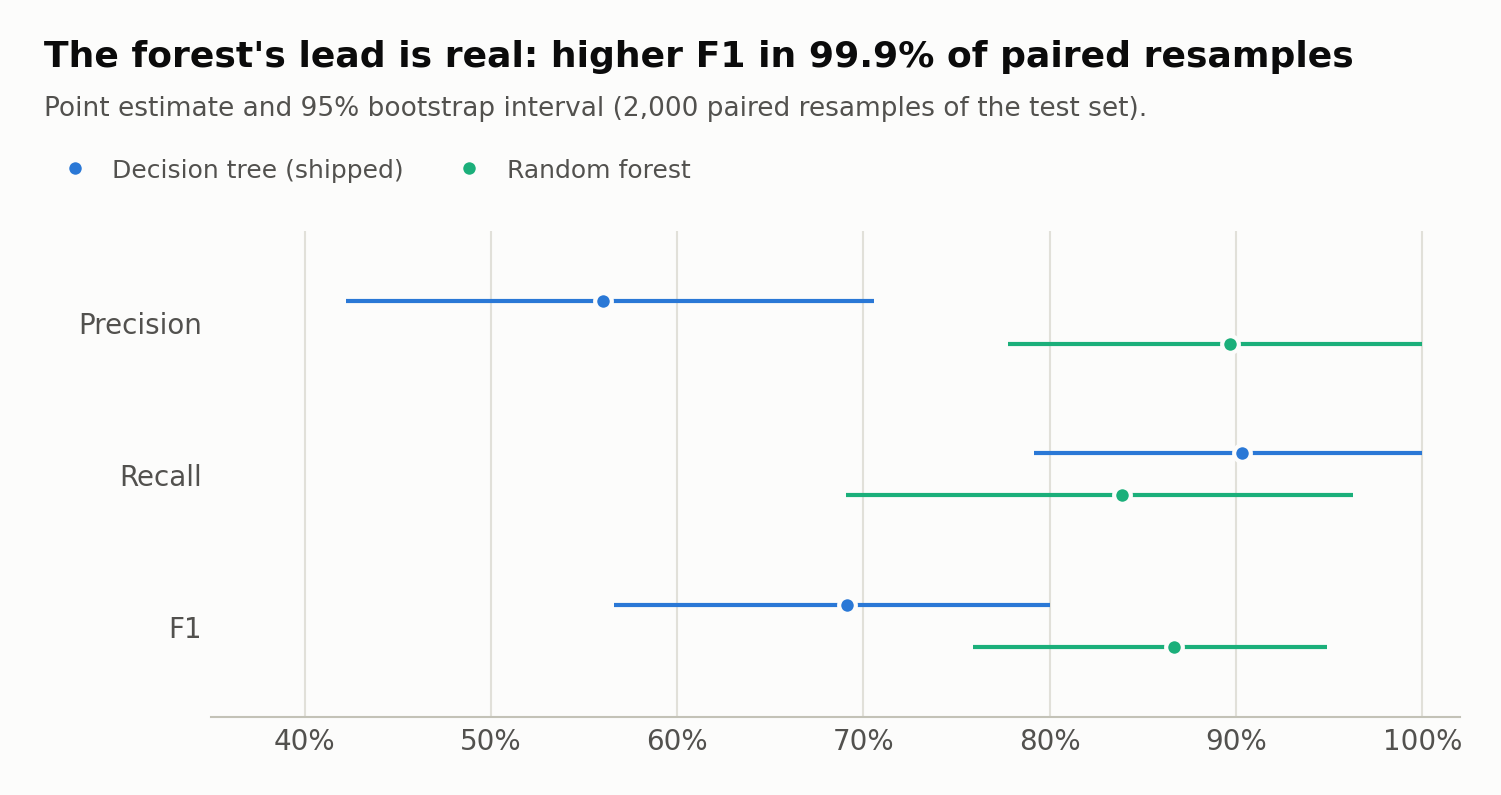

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.9))
legend_y = S.heading(
    fig,
    "The forest's lead is real: higher F1 in {:.1%} of paired resamples".format(f1_gap["share_of_resamples_b_better"]),
    "Point estimate and 95% bootstrap interval (2,000 paired resamples of the test set).",
    left=0.12,
)
metric_order = ["precision", "recall", "f1"]
metric_names = {"precision": "Precision", "recall": "Recall", "f1": "F1"}
rows_y = np.arange(len(metric_order))[::-1].astype(float)
for offset, name in ((0.14, A.TREE), (-0.14, A.FOREST)):
    rows = uncertainty[uncertainty["model"] == name].set_index("metric").loc[metric_order]
    ypos = rows_y + offset
    color = S.MODEL_COLORS[name]
    ax.hlines(ypos, rows["ci_low"], rows["ci_high"], color=color, linewidth=S.LINE_W)
    ax.plot(rows["estimate"], ypos, "o", ms=S.MARKER, color=color, mec=S.SURFACE, mew=S.RING,
            label=name, zorder=5)
ax.set_yticks(rows_y, [metric_names[m] for m in metric_order])
ax.set_xlim(0.35, 1.02)
ax.set_ylim(-0.6, len(metric_order) - 0.4)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
S.legend(fig, legend_y, ncol=2)

S.save(fig, FIG / "03_uncertainty.png")
display(Image(filename=FIG / "03_uncertainty.png", width=760, alt="Bootstrap 95 percent intervals. The random forest has higher precision and F1 than the shipped tree; the tree has slightly higher recall; the tree's intervals are wide."))

The forest's F1 advantage holds in almost every resample, so the interpretability trade-off costs real performance. It isn't an artefact of a small test set. The tree's recall interval is wide (roughly 79–100%). That's what 31 positive cases buy you, and it's the main reason a real deployment would need far more labelled history.

## 5. Fairness audit

Two decision trees, identical settings, identical biased labels. The only difference is that one was also allowed to see the vendor's region. Each bar shows the false-alarm rate on **truly clean** invoices: how often an innocent vendor's payment gets held. Whiskers are 95% Wilson intervals.

In [10]:
fairness = A.fairness_table(test, preds[A.TREE], preds[A.NAIVE])
fairness.pivot(index="region", columns="model", values="rate").sort_values(A.NAIVE, ascending=False)

model,Decision tree (shipped),Decision tree + region
region,,
South Asia,0.160,0.617
North America,0.025,0.033
Latin America,0.009,0.018
Europe,0.023,0.016
East Asia,0.000,0.000


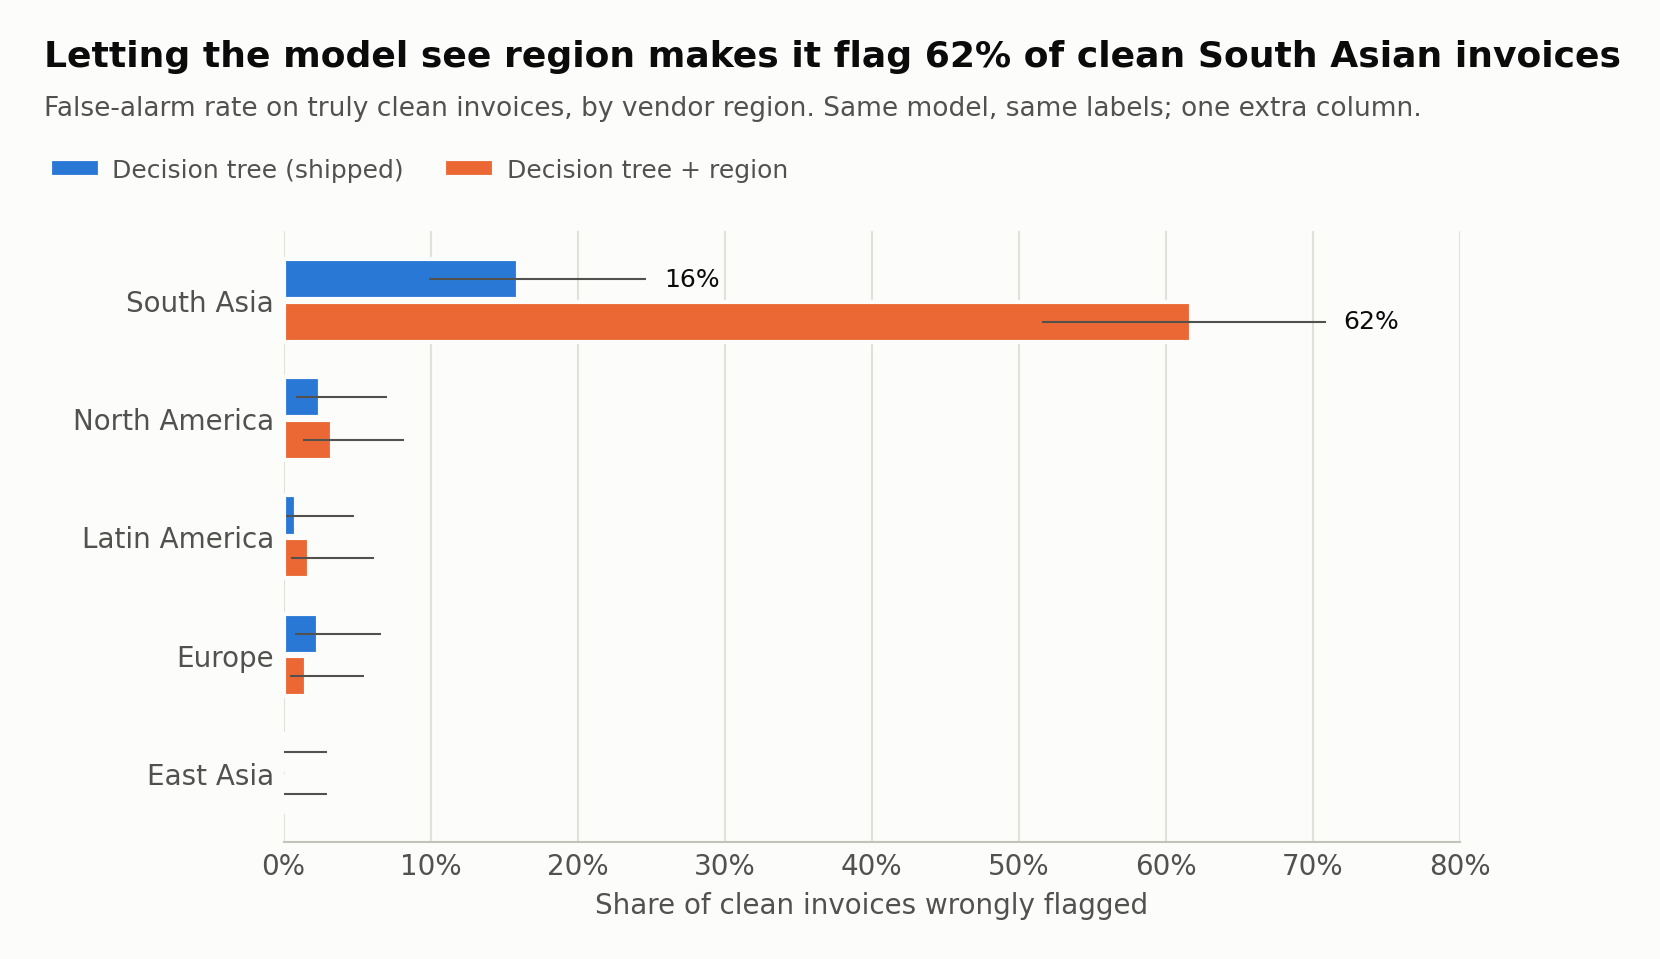

In [11]:
regions = (fairness[fairness["model"] == A.NAIVE].sort_values("rate")["region"].tolist())
fig, ax = plt.subplots(figsize=(8, 4.6))
legend_y = S.heading(
    fig,
    "Letting the model see region makes it flag 62% of clean South Asian invoices",
    "False-alarm rate on truly clean invoices, by vendor region. Same model, same labels; one extra column.",
    left=0.165,
)
height = 0.34
for offset, name in ((height / 2 + 0.01, A.TREE), (-(height / 2 + 0.01), A.NAIVE)):
    part = fairness[fairness["model"] == name].set_index("region").loc[regions]
    ypos = np.arange(len(regions)) + offset
    ax.barh(ypos, part["rate"], height=height, color=S.MODEL_COLORS[name], edgecolor=S.SURFACE,
            linewidth=S.GAP, label=name)
    ax.hlines(ypos, part["ci_low"], part["ci_high"], color=S.INK_2, linewidth=S.HAIRLINE)
    top = part.loc["South Asia"]
    ax.text(max(top["rate"], top["ci_high"]) + 0.012, ypos[regions.index("South Asia")],
            f"{top['rate']:.0%}", va="center", fontsize=9, color=S.INK)

ax.set_yticks(np.arange(len(regions)), regions)
ax.set_xlim(0, 0.8)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Share of clean invoices wrongly flagged")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
S.legend(fig, legend_y, ncol=2)

S.save(fig, FIG / "04_fairness.png")
display(Image(filename=FIG / "04_fairness.png", width=760, alt="False-alarm rate on clean invoices by region. With region as a feature, 62 percent of clean South Asian invoices are flagged; without it, 16 percent. All other regions stay under about 3 percent for both models."))

Two findings, and the second is the more important one:

1. **The region-aware model learned the historical bias and called it a pattern.** It flags about three in five clean South Asian invoices, and its overall precision is *lower*. Bias didn't buy accuracy here; it reproduced the labels.
2. **Removing the column reduced the disparity but did not remove it.** Even without region, clean South Asian invoices are flagged at about 16%, and the interval's lower bound sits above every other region's upper bound. The biased labels are still in the training data, and the model reaches some of the same conclusions through behavioural features. Dropping a sensitive column is a first step, not a fix. The labels themselves would need to be re-adjudicated.

## 6. What drives the decisions

**Permutation importance** on the held-out test set: shuffle one feature and measure how much average precision drops. It uses the same measurement for every model, on data none of them trained on. Built-in importances aren't comparable: a tree's split gain and a regression's coefficients measure different things, on training data.

In [12]:
from features import FEATURE_SHORT as SHORT
importance = A.importance_table(bundle, test)
wide = importance.pivot(index="feature", columns="model", values="importance")[[A.TREE, A.FOREST, A.LOGISTIC]]
wide = wide.sort_values(A.TREE, ascending=False)
wide.rename(index=SHORT)

model,Decision tree (shipped),Random forest,Logistic regression
feature,,,
Gap since vendor's last invoice (× usual),0.420,1.381e-01,5.278e-01
Text match to closest earlier invoice,0.327,8.513e-02,-4.816e-05
Vendor age,0.269,2.691e-02,6.226e-03
Round-number amount,0.223,3.987e-02,9.874e-03
Days since bank-detail change,0.152,9.383e-02,8.276e-04
Has purchase order,0.142,3.736e-02,8.986e-02
Closest earlier invoice credited back,0.090,2.099e-02,4.488e-02
Amount (× vendor's usual),0.071,2.746e-02,9.844e-02
Days since closest earlier invoice,0.060,6.207e-02,5.157e-04


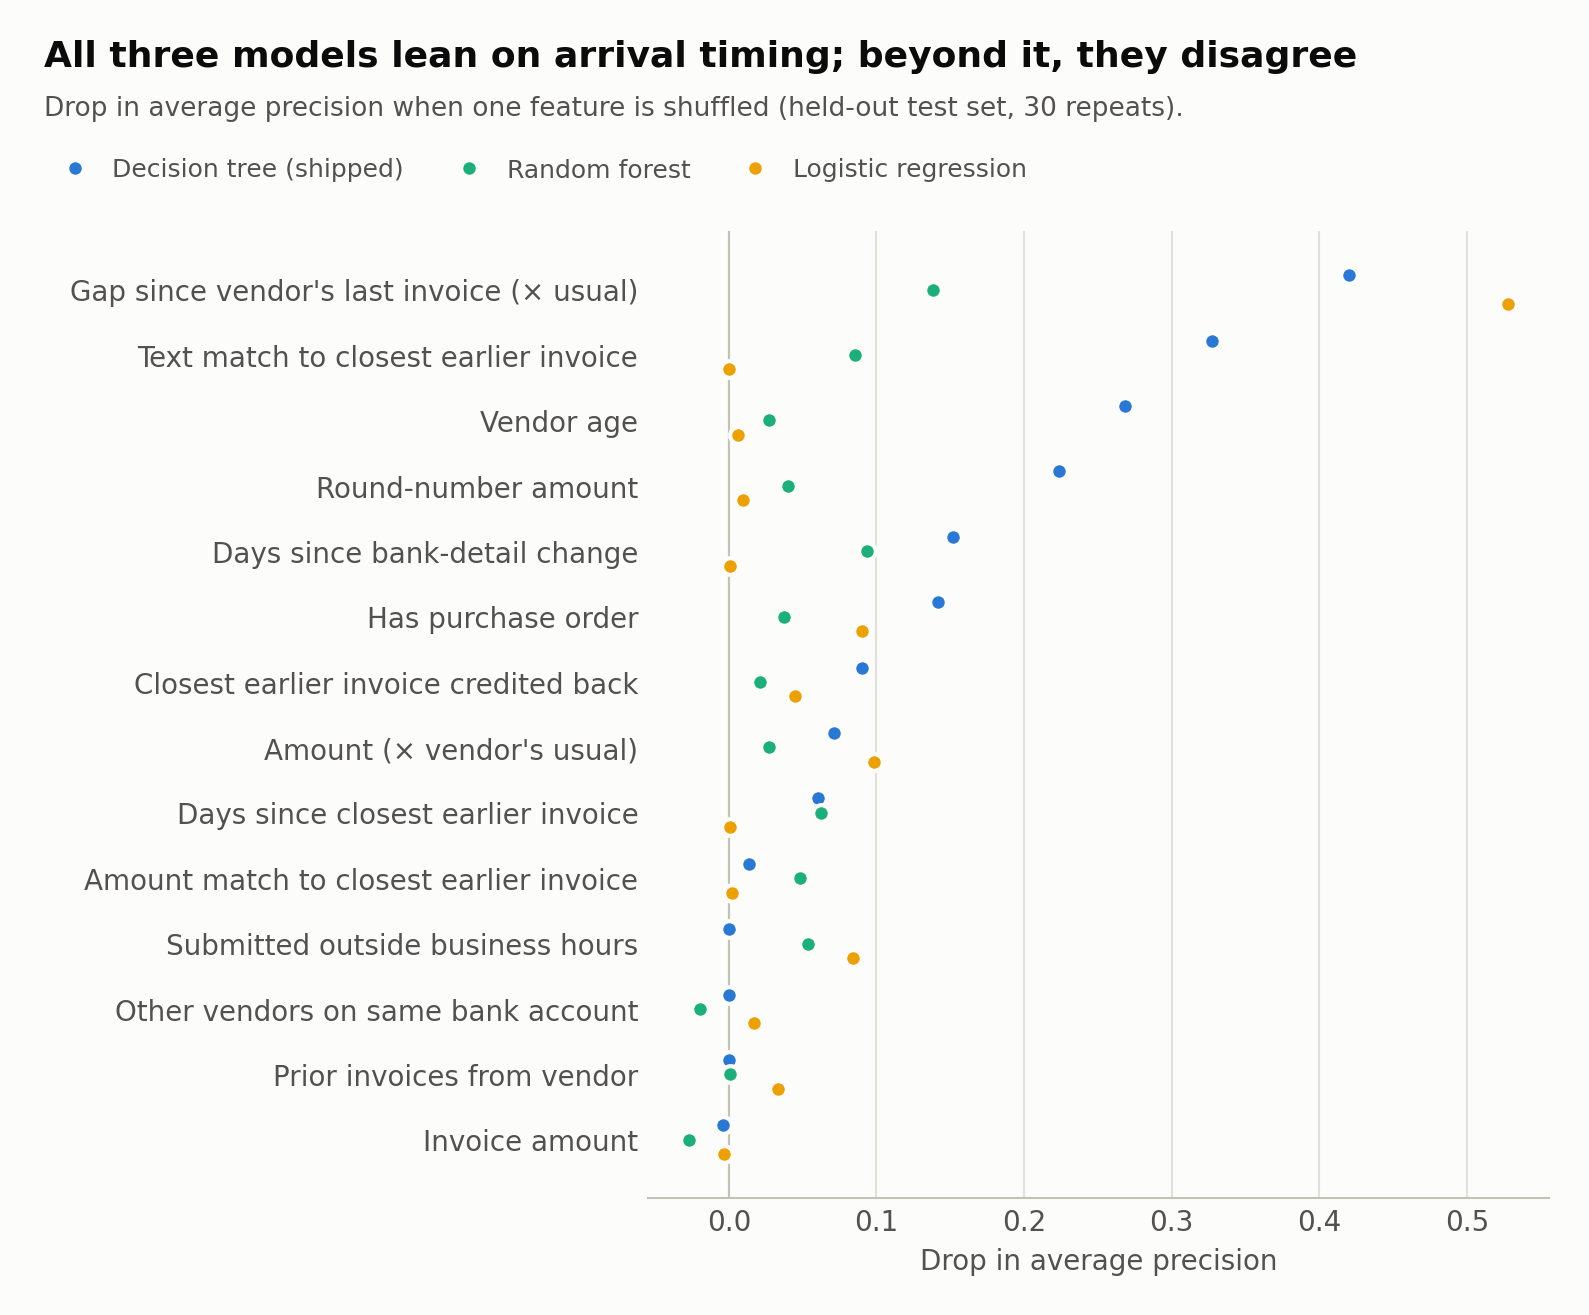

In [13]:
features_desc = wide.index.tolist()
ypos_base = np.arange(len(features_desc))[::-1].astype(float)
fig, ax = plt.subplots(figsize=(8.5, 6.6))
legend_y = S.heading(
    fig,
    "All three models lean on arrival timing; beyond it, they disagree",
    "Drop in average precision when one feature is shuffled (held-out test set, 30 repeats).",
    left=0.37,
)
for offset, name in ((0.22, A.TREE), (0.0, A.FOREST), (-0.22, A.LOGISTIC)):
    ax.plot(wide.loc[features_desc, name].to_numpy(), ypos_base + offset, "o", ms=S.MARKER,
            color=S.MODEL_COLORS[name], mec=S.SURFACE, mew=S.RING, label=name, zorder=5, linestyle="none")
ax.axvline(0, color=S.BASELINE, linewidth=S.HAIRLINE)
ax.set_yticks(ypos_base, [SHORT[f] for f in features_desc])
ax.set_xlabel("Drop in average precision")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
S.legend(fig, legend_y, ncol=3)

S.save(fig, FIG / "05_permutation_importance.png")
display(Image(filename=FIG / "05_permutation_importance.png", width=800, alt="Permutation importance for three models. Arrival timing versus the vendor's rhythm is the top feature for all three; beyond that the models rank features differently."))

The engineered timing feature is the most important signal for all three models, which supports the feature-engineering argument from section 2. Beyond it, the models disagree: the regression leans almost entirely on timing, while the tree also uses text similarity, vendor age and round amounts. None of them is wrong. Importance describes how a particular model used the data, not what causes fraud.

## 7. What the agent does to the payment run

The agent turns the shipped model's score into an action: **escalate** (block payment, confirm with the vendor out of band) at 0.75 and above, **hold** for analyst review from 0.35, **release** below that.

In [14]:
routing = A.routing_table(test, probs[A.TREE])
display(routing)

reviewed = routing.loc[["ESCALATE", "HOLD"], "invoices"].sum() / routing["invoices"].sum()
fraud_dollars_intercepted = routing.loc[["ESCALATE", "HOLD"], "fraud_dollars"].sum() / routing["fraud_dollars"].sum()
print(f"Analysts review {reviewed:.1%} of the queue; that slice holds {fraud_dollars_intercepted:.1%} of fraudulent dollars.")

,invoices,fraudulent,fraud_dollars,share_of_queue,share_of_fraud
action,,,,,
ESCALATE,37,28,1.047e+06,0.060,0.903
HOLD,37,0,0.000e+00,0.060,0.000
RELEASE,540,3,8.148e+04,0.879,0.097


Analysts review 12.1% of the queue; that slice holds 92.8% of fraudulent dollars.


Two things are worth noticing. The escalate queue does almost all the work. The **hold** band caught no fraud at all on this test set: every invoice in it was clean. The thresholds were set by policy rather than fitted, and this is the evidence that the middle band should be re-examined, either narrowed or tuned on validation cost like the model's own settings.

## 8. The agent's reasoning on three cases

For each invoice the agent recovers the literal rule chain the tree followed and the records behind it: the earlier invoice it matched, the bank-detail change, the vendor's history. In the live demo these are narrated into an analyst memo by Claude. Claude is never asked whether an invoice is fraud; it only describes evidence the model and the records already produced. Here the evidence is shown directly.

In [15]:
import demo
from agent import load_agent

model, full_ledger, changes = load_agent()
for label, case, record in demo.pick_cases(test, model, full_ledger, changes):
    demo.show(label, case, record, narrate=False)


VENDOR IMPERSONATION
  invoice     INV-43012   vendor V1017
  amount      $181,597.26
  risk score  0.86
  decision    !!  ESCALATE - block payment, notify treasury, confirm with vendor out of band

  the model's reasoning, in full:
    1. how early this invoice arrived against the vendor's own billing rhythm
       measured 0.08  |  rule: gap_vs_vendor_cadence <= 0.67
    2. the invoice it resembles was credited back, making this a legitimate rebill
       measured 0.00  |  rule: closest_match_was_credited <= 0.50
    3. backed by a purchase order
       measured 1.00  |  rule: has_purchase_order > 0.50
    4. days since this vendor's bank details changed
       measured 5.00  |  rule: days_since_bank_change <= 10.50
    5. how early this invoice arrived against the vendor's own billing rhythm
       measured 0.08  |  rule: gap_vs_vendor_cadence <= 0.17

  closest prior invoice   INV-40414
    $49,264.88 on day 604, 1 day before this one
    text match 95%, amount differs by $132,332

The third case is the one a keyword rule gets wrong. The invoice is 98% text-identical to one from eight days earlier, $130 apart, with no purchase order, and it's legitimate: the earlier invoice was credited back, so this is a corrected rebill. The model releases it.

## Limitations

- **Synthetic data.** Every result measures recovery of planted patterns. It shows the method works, not what accuracy would be on a real ledger.
- **Inflated fraud rate** (~5% vs well under 1% in practice), so there are enough positives to learn from. Real class imbalance would be much harsher.
- **Small test set.** 31 fraud cases leaves wide intervals (section 4).
- **The bias level is a chosen parameter.** 20% of clean invoices from one region carry a false label. The fairness effect persists across roughly 15–28%, but the exact numbers depend on that choice.
- **No adversary.** A fraudster who knew the model watched billing rhythm would simply wait. Real deployment would need monitoring for drift and adaptation.